# 08 · Nieuwe gegevens toevoegen en een voederstrategie beoordelen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

De toestellen blijven meten terwijl je het bedrijf opvolgt. Een overzicht op de kantoorcomputer moet daarom bijgewerkt kunnen worden. In deze oefening voeg je de resterende meetdagen toe en controleer je of de gegevens langs dezelfde weg op de juiste plaats terechtkomen.

Daarna vergelijk je de eerdere resultaten met de aanvullende periode en de gehele periode. Je maakt voor elk hok grafieken van gemiddelde groei, voederopname en voederconversie. Je onderzoekt welke voederstrategie bij de patronen zou kunnen passen en kiest welke strategie je op dit bedrijf verder zou willen gebruiken.

**Nodig:** notebook 07 afgerond, dezelfde Codespace en eigen branch, je werkdatabase uit 02 en een partner met de andere gegevensrol. Beide servers en hun ontvangprogramma's moeten bereikbaar zijn. Je bewaart de beginsituatie uit 07 en maakt nieuwe bestanden voor deze oefening.

De inlevering bestaat uit dit ingevulde notebook, automatisch gemaakte tabellen en figuren, een controlebestand en een databasesnapshot. Je schrijft geen afzonderlijk verslag. Je antwoorden en beslissingen staan bij de betreffende opdrachten.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Voorwaarde voor deze versie.** Voer eerst notebook 07 met FILTER = '0' uit. Een oudere beginsituatie wordt geweigerd omdat de rekenmethode verschilt. Volg de archiefinstructie in 07 en behoud de oude bestanden ter vergelijking. Alle fasetabellen en aanvullende berekeningen gebruiken dezelfde verplichte selectie.

</div>

## 1. De beginsituatie terugvinden

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

De opgeslagen beginsituatie maakt zichtbaar wat je vóór de aanvulling wist. Een vergelijking is alleen eerlijk als je ook de oude rekenregels en tijdsgrenzen kent. De eerste cel leest deze informatie en controleert of de tabellen nog overeenkomen met de controlewaarden uit 07.

Open deze notebook met dezelfde Python-kernel als bij 07. De Excel-lezer staat in `requirements.txt`. Als je bestaande Codespace nog geen `openpyxl` heeft, voer je eerst de volgende cel uit.

</div>

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("openpyxl") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl>=3.1,<4"])

In [2]:
_DOCENT_BRANCH_OVERRIDE = "student/proefdocent"

In [3]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import closing
from getpass import getpass
import hashlib, ipaddress, json, re, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hoofdmap = Path(subprocess.check_output(["git", "rev-parse", "--show-toplevel"], text=True).strip())
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=hoofdmap, text=True).strip()
if not re.fullmatch(r"student/[a-z0-9][a-z0-9_-]*", branch) and "_DOCENT_BRANCH_OVERRIDE" in globals():
    branch = _DOCENT_BRANCH_OVERRIDE
inlever = hoofdmap / "gegevens/inlevering"
werk = hoofdmap / "gegevens/werk"
instellingen = json.loads((inlever / "01_werkplekcontrole.json").read_text(encoding="utf-8"))
deelnemer, rol = instellingen["deelnemerscode"], instellingen["rol"]
if branch != "student/" + deelnemer or instellingen.get("branch") != branch or rol not in ("gewichten", "voederopname"):
    raise ValueError("Controleer je eigen branch en rol uit notebook 01.")
sys.path[:0] = [str(hoofdmap / "programmatuur"), str(hoofdmap / "server")]
from aanvulling_08 import lees_excel, voeg_toe, lees_basis, vergelijk_basis, uitgebreide_analyse, snapshot
from analyse_07 import lees_analyse, vat_hokken_samen
from figuren_07 import gewichtsfiguur, intervalfiguur, hokvolgorde
from publiceren import lees_metingen, meettopic, MqttSessie
from beginset_publiceren import publiceer_beginset
from meetgegevens import selectie_manifest
from api_ophalen import ApiClient, werk_analyse_bij

basisinfo, basistabellen = lees_basis(inlever / "beginsituatie_07")
controle07 = json.loads((inlever / "07_analysecontrole.json").read_text(encoding="utf-8"))
if controle07["deelnemerscode"] != deelnemer or controle07["basis"] != basisinfo:
    raise ValueError("Je controlebestand en beginsituatie uit 07 horen niet bij elkaar.")
bron = "asserva" if rol == "gewichten" else "schauer"
bronpad = werk / (bron + ".db")
analysepad = werk / "analyse_06.db"
maakcontrole = json.loads((hoofdmap / "gegevens/aanvulling/maakcontrole.json").read_text(encoding="utf-8"))
excelpad = hoofdmap / "gegevens/aanvulling" / (bron + "_aanvullende_metingen.xlsx")
server = json.loads((werk / "server.json").read_text(encoding="utf-8"))
if server["deelnemerscode"] != deelnemer:
    raise ValueError("Gebruik je eigen serverinstellingen.")
serveradres = str(ipaddress.IPv4Address(server["ipv4"]))
ca = werk / "ca.crt"
print("Rol:", rol, "| Laatste basisdag: 20 september 2023")
display(pd.DataFrame(basisinfo["bronnen"]).T[["aantal"]])
display(basistabellen["hokresultaten.csv"][["hok", "interval", "dieren_bruikbaar", "voederconversie"]].head())

Rol: gewichten | Laatste basisdag: 20 september 2023


,aantal
asserva,80028
schauer,146649


,hok,interval,dieren_bruikbaar,voederconversie
0,1,1,10,1.056736
1,1,2,11,1.031197
2,1,3,11,1.335039
3,1,4,11,1.266819
4,10,1,6,1.204890


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>De beginsituatie bevat 80.028 gewichtsrecords en 146.649 voederrecords. De analyse omvat 101 gekoppelde dieren in tien hokken. Niet ieder dier is in ieder interval bruikbaar. De bewaarde bestanden blijven het vergelijkingspunt, ook als je deze notebook later opnieuw uitvoert.</div>

## 2. De aanvulling in Excel onderzoeken

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** op je eigen laptop (Excel of een ander programma dat `.xlsx` opent)

Download vanuit `gegevens/aanvulling/` het bestand dat bij je rol hoort. Open het zonder het te wijzigen. Het blad `toelichting` beschrijft de gegevens. De meetbladen `week_5` en `resterende_dagen` bevatten respectievelijk 21–27 september en 28 september–5 oktober. Samen zijn dit vijftien kalenderdagen.

**Stap 1.** Bekijk de eerste rij van elk meetblad en zoek `ROW_ID`, `EID`, `PEN`, `DATE` en je meetveld (`VBW` of `VFI`). Klik een cel in `ROW_ID` aan en bekijk de volledige inhoud in de formulebalk. Deze lange code is tekst, zodat geen cijfers verloren gaan.

**Stap 2.** Vergelijk enkele waarden met de veldbeschrijving op `toelichting`. Zoek ook `ERROR` en `FILTER`. De aanvulling bevat de oorspronkelijke kwaliteitsinformatie. Het importeren en het selecteren van geschikte analysegegevens zijn afzonderlijke stappen.

**Stap 3.** Sluit Excel zonder op te slaan. Gebruik in Codespaces het vrijgegeven bestand uit de repository. Je hoeft deze grote tabellen niet handmatig over te typen. De volgende cel leest beide meetbladen, controleert de bestandshash en toont alleen de meetkolommen die je nodig hebt.

</div>

In [4]:
rijen, bladoverzicht = lees_excel(excelpad, maakcontrole[bron])
display(bladoverzicht)
meetveld = "VBW" if rol == "gewichten" else "VFI"
voorbeeld = pd.DataFrame(rijen[:5])
display(voorbeeld[["ROW_ID", "EID", "PEN", "DATE", meetveld, "FILTER"]])
print("Aantal aanvullende records:", len(rijen))

,werkblad,records,eerste_datum,laatste_datum
0,week_5,23546,2023-09-21,2023-09-27
1,resterende_dagen,28648,2023-09-28,2023-10-05


,ROW_ID,EID,PEN,DATE,VBW,FILTER
0,898707301695254512000000000,89870730,2,2023-09-21,16.776518,0
1,897280761695254606000000000,89728076,7,2023-09-21,19.650000,0
2,897280621695254609000000000,89728062,1,2023-09-21,20.510000,flagged
3,897280601695254613000000000,89728060,2,2023-09-21,18.160000,0
4,898707481695254615000000000,89870748,4,2023-09-21,19.370000,0


Aantal aanvullende records: 52194


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 1.** Wat kan door de aanvulling veranderen aan je overzicht, en wat verwacht je bij een herberekening van precies dezelfde oude periode?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 1):**

*Voeg hier je antwoord in. Tip: Maak onderscheid tussen meer records, een langere periode en gewijzigde oude waarden.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 1**

Er komen 52.194 gewichtsrecords of 86.952 voederrecords bij, afhankelijk van mijn rol. De partner voegt de andere bron toe. De langere periode kan een andere gemiddelde groei en conversie geven. Over de vaste basisperiode verwacht ik dezelfde uitkomsten als de bronrecords, populatie en tijdslokale methode gelijk blijven. Meer gegevens garanderen geen gunstigere conversie.

</div>

## 3. Toevoegen aan de computer van het toestel

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

Je werkdatabase stelt de computer van het eigen toestel voor. Je voegt de nieuwe bronrecords hier toe. De analysedatabase op de kantoorcomputer krijgt ze later via de API.

De code maakt eerst een consistente back-up van je huidige werkdatabase. Daarna voegt ze de Excel-records in één transactie toe. Als een bestaande identificatie een andere inhoud heeft, wordt de hele toevoeging teruggedraaid. Identieke records worden herkend en blijven één keer aanwezig.

Bekijk het getoonde doelbestand vóór je de invoercel uitvoert. Het moet `gegevens/werk/asserva.db` of `gegevens/werk/schauer.db` zijn. De tabel `hokken` blijft behouden. Gebruik na deze stap geen oudere laptopkopie om het bijgewerkte werkbestand te vervangen.

</div>

In [5]:
print("Toevoegen aan:", bronpad.relative_to(hoofdmap))
backuppad = werk / (bron + "_voor_08.db.gz")
if not backuppad.exists():
    snapshot(bronpad, backuppad)
importcontrole = voeg_toe(bronpad, rijen, maakcontrole[bron])
display(pd.DataFrame([importcontrole]))
herhaalimport = voeg_toe(bronpad, rijen, maakcontrole[bron])
assert herhaalimport["nieuw"] == 0
assert herhaalimport["na"] == importcontrole["na"]
with closing(sqlite3.connect(bronpad.as_uri() + "?mode=ro", uri=True)) as db:
    display(pd.read_sql_query("SELECT MIN(DATE) AS eerste_datum, MAX(DATE) AS laatste_datum, COUNT(*) AS records FROM metingen", db))
print("Herhaalde import:", herhaalimport)

Toevoegen aan: gegevens/werk/asserva.db


,voor,nieuw,ongewijzigd,na
0,80028,52194,0,132222


,eerste_datum,laatste_datum,records
0,2023-08-24,2023-10-05,132222


Herhaalde import: {'voor': 132222, 'nieuw': 0, 'ongewijzigd': 52194, 'na': 132222}


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>Bij de eerste uitvoering worden 52.194 gewichtsrecords of 86.952 voederrecords toegevoegd. Daarna bevat de gewichtsbron 132.222 records of de voederbron 233.601 records. Bij herhaling is het aantal nieuwe records nul. Een nul bij herhaling betekent dus dat de eerdere toevoeging behouden is.</div>

## 4. Beide gegevensstromen opnieuw laten aankomen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** samen met je partner, in Codespaces en op de eigen DigitalOcean-server

Controleer eerst of beide ontvangprogramma's actief zijn. Anders kan een broker de berichten al hebben doorgestuurd voordat de ontvanger aanwezig is. Je gebruikt dezelfde accounts en certificaten als in 04–06. Er worden geen nieuwe servers of accounts aangemaakt.

**Stap 1.** Open in Codespaces een terminal en gebruik de volgende afgedrukte SSH-opdracht. Meld je aan met je **`SSH beheer-wachtwoord`**.

</div>

In [6]:
print(f"ssh -o StrictHostKeyChecking=ask beheer@{serveradres}")

ssh -o StrictHostKeyChecking=ask beheer@127.0.0.1


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** op de eigen DigitalOcean-server (SSH-terminal)

**Stap 2.** Start de bestaande diensten handmatig. `start` is ook bruikbaar als een dienst al draait. Na een serverherstart start je de broker opnieuw op deze manier. De API gebruikt in deze reeks de dienstnaam `iot-status`.

</div>

```bash
sudo systemctl start mosquitto iot-ontvanger iot-status nginx
```

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Als `sudo` om een wachtwoord vraagt, gebruik je **`SSH beheer-wachtwoord`**. Wacht tot de opdracht klaar is. Controleer daarna de toestand met de volgende afzonderlijke opdracht.

</div>

```bash
sudo systemctl is-active mosquitto iot-ontvanger iot-status nginx
```

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Je verwacht viermaal `active`. De partner voert deze controle uit op de eigen server. Bij een fout volg je de herstelinstructies uit 05 of 06 voordat je publiceert. Sluit de SSH-sessie met de volgende opdracht.

</div>

```bash
exit
```

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

**Stap 3.** Spreek met je partner af dat beide ontvangers gereed zijn. Voer daarna elk de publicatiecel uit. De selectie bevat uitsluitend records met een datum vanaf 21 september. De oude beginset hoeft niet opnieuw verstuurd te worden.

De publicatie gebruikt groepen van honderd berichten en toont voortgang. Een bevestiging van de broker betekent dat de broker het bericht heeft aanvaard. Je controleert daarna afzonderlijk of de volledige inhoud in de serverdatabase staat. Bij een onderbreking mag je dezelfde selectie opnieuw publiceren.

</div>

In [7]:
def aanvullende_berichten():
    return (b for b in lees_metingen(bronpad, rol, deelnemer, None)
            if "2023-09-21" <= b["bronrecord"]["DATE"] < "2023-10-06")

verwacht_eigen = selectie_manifest(lees_metingen(bronpad, rol, deelnemer, None))
wachtwoord = getpass("MQTT-broker eigenaar: ")
try:
    with MqttSessie(serveradres, ca, wachtwoord) as sessie:
        gepubliceerd = publiceer_beginset(sessie, meettopic(deelnemer, rol), aanvullende_berichten())
finally:
    del wachtwoord
assert gepubliceerd == maakcontrole[bron]["aantal"]
broncontrole = {"deelnemerscode": deelnemer, "rol": rol, "bronnen": verwacht_eigen}
(inlever / "08_eigen_broncontrole.json").write_text(json.dumps(broncontrole, indent=2) + "\n", encoding="utf-8")
print("Bewaar en deel 08_eigen_broncontrole.json met je partner.")

5000 publicaties door de broker bevestigd


10000 publicaties door de broker bevestigd


15000 publicaties door de broker bevestigd


20000 publicaties door de broker bevestigd


25000 publicaties door de broker bevestigd


30000 publicaties door de broker bevestigd


35000 publicaties door de broker bevestigd


40000 publicaties door de broker bevestigd


45000 publicaties door de broker bevestigd


50000 publicaties door de broker bevestigd


Gereed: 52194 publicaties bevestigd. Controleer nu de opslag op beide servers.
Bewaar en deel 08_eigen_broncontrole.json met je partner.


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Stap 4.** Download `gegevens/inlevering/08_eigen_broncontrole.json` en bezorg dit bestand aan je partner. Het bevat aantallen en inhoudsvingerafdrukken, geen wachtwoorden. Upload het bestand van je partner naar `gegevens/werk/` en geef het daar de naam `08_partner_broncontrole.json`. Zo kan iedere kantoorcomputer ook de inhoud van de andere bron controleren.

**Stap 5.** Voer de volgende cel pas uit nadat beide publicaties klaar zijn. De API leest de verzameldatabase op je eigen server. Aantallen én inhoudsvingerafdrukken moeten overeenkomen met de twee broncontroles. Als de ontvangst nog bezig is, wacht je tot de partner gereed is en herhaal je de controlecel.

</div>

In [8]:
partner = json.loads((werk / "08_partner_broncontrole.json").read_text(encoding="utf-8"))
andere_bron = "schauer" if bron == "asserva" else "asserva"
andere_rol = "voederopname" if rol == "gewichten" else "gewichten"
if partner["deelnemerscode"] == deelnemer or partner["rol"] != andere_rol or set(partner["bronnen"]) != {andere_bron}:
    raise ValueError("Gebruik de actuele broncontrole van je partner met de andere rol.")
verwacht = {**verwacht_eigen, **partner["bronnen"]}
assert verwacht["asserva"]["aantal"] == 132222 and verwacht["schauer"]["aantal"] == 233601
api = ApiClient("https://" + serveradres, ca, getpass("API-Droplet wachtwoord: "))
try:
    servermeta = api.ophalen("/metadata")
    if servermeta["bronnen"] != verwacht:
        raise ValueError("De serverinhoud is nog niet gelijk aan beide bijgewerkte bronnen. Controleer de ontvangers en publiceer zo nodig opnieuw.")
finally:
    api.sluiten()
display(pd.DataFrame(servermeta["bronnen"]).T[["aantal"]])

,aantal
asserva,132222
schauer,233601


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 2.** Waarom zijn zowel de brokerbevestiging als de servercontrole nodig?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 2):**

*Voeg hier je antwoord in. Tip: Benoem welk programma de SQL-records opslaat.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 2**

De MQTT-broker bevestigt de ontvangst van mijn publicatie. Het ontvangprogramma schrijft de meting daarna in SQLite. Dat programma kan uitgeschakeld zijn of een bericht afwijzen. Pas de vergelijking van aantallen en inhoudsvingerafdrukken toont dat de serverdatabase overeenkomt met beide bronnen.

</div>

## 5. De kantoorcomputer bijwerken via de API

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

Je vraagt nu de verzamelde gegevens op met dezelfde lees-API als in 06. De import controleert alle records en voegt alleen ontbrekende identificaties toe aan `analyse_06.db`. De bestandsnaam blijft behouden omdat dit dezelfde analysedatabase is. De controlebestanden uit 06 en 07 beschrijven hun eerdere toestand.

De API wordt volledig doorlopen om ook de behouden records te controleren. Dat kost meer overdracht dan alleen een datumfilter, maar maakt de volledigheidscontrole eenvoudig. Laat de cel afwerken. Je partner mag de gegevens tijdens deze controle niet veranderen. Bij een fout wordt deze import teruggedraaid.

</div>

In [9]:
api = ApiClient("https://" + serveradres, ca, getpass("API-Droplet wachtwoord: "))
try:
    api_import = werk_analyse_bij(api.ophalen, analysepad)
    assert api_import["bronnen"] == verwacht
    api_herhaling = werk_analyse_bij(api.ophalen, analysepad)
    assert api_herhaling["nieuw"] == 0 and api_herhaling["bronnen"] == verwacht
finally:
    api.sluiten()
data, eindmanifest = lees_analyse(analysepad)
print("Totaal op de kantoorcomputer:", len(data))
print("Nieuwe records bij deze API-import:", api_import["nieuw"])
print("Nieuwe records bij herhaling:", api_herhaling["nieuw"])

25,000 records gecontroleerd


50,000 records gecontroleerd


75,000 records gecontroleerd


100,000 records gecontroleerd


125,000 records gecontroleerd


150,000 records gecontroleerd


... (21 outputs left out)

325,000 records gecontroleerd


350,000 records gecontroleerd


Klaar: 0 nieuwe records, 365,823 ongewijzigde records.


Totaal op de kantoorcomputer: 365823
Nieuwe records bij deze API-import: 139146
Nieuwe records bij herhaling: 0


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>Bij de eerste volledige aanvulling komen 139.146 records bij. De analysedatabase bevat daarna 365.823 records. Bij opnieuw uitvoeren kunnen er al nul nieuwe records zijn. De totalen en inhoudsvingerafdrukken moeten in beide gevallen gelijk zijn. De rechtstreekse Excel-import gebeurt uitsluitend in de brondatabase.</div>

## 6. Controleren wat gelijk blijft en wat verandert

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

Eerst bereken je de vier oorspronkelijke intervallen opnieuw met uitsluitend de oorspronkelijke bronperiode. Je vergelijkt ook de populatie, daggewichten en dierintervallen met de opgeslagen beginsituatie. De CSV-bestanden bewaren twaalf significante cijfers. Daarom gebruikt de vergelijking een kleine numerieke tolerantie van 10⁻¹⁰ in plaats van een exacte vergelijking van binaire kommagetallen.

Daarna verleng je de analyse. De dagelijkse gewichtsmediaan, de maximale interpolatieafstand van 48 uur en de controle op voederdagen blijven gelijk. De langere periode kan wel een andere groep bruikbare dieren opleveren. Die aantallen staan bij de uitkomsten.

</div>

In [2]:
display(data.groupby(["bron", "vlag"], dropna=False).size().rename("rijen").reset_index())
print("Alle berekeningen hieronder gebruiken uitsluitend FILTER = '0'.")
oude_hokken = vergelijk_basis(data, basisinfo, basistabellen)
print("Beginsituatie opnieuw berekend: gelijk gebleven.")
resultaat = uitgebreide_analyse(data, basistabellen["populatie.csv"])
display(resultaat["audit"])
display(resultaat["dierintervallen"].groupby(["interval", "vanaf", "tot"]).agg(
    dieren=("dier_id", "size"), bruikbaar=("bruikbaar", "sum")))

,bron,vlag,rijen
0,asserva,0,115463
1,asserva,errored,13
2,asserva,flagged,16746
3,schauer,0,110294
4,schauer,errored,138
5,schauer,flagged,123169


Alle berekeningen hieronder gebruiken uitsluitend FILTER = '0'.


Beginsituatie opnieuw berekend: gelijk gebleven.


,stap,bron,over,uitgesloten
0,Gekozen bronperiode,asserva,132222,0
1,Gekozen bronperiode,schauer,233601,0
2,Geldige herkenning,asserva,132209,13
3,Geldige herkenning,schauer,233463,138
4,Stabiel gekoppelde dieren,asserva,132209,0
5,Stabiel gekoppelde dieren,schauer,233463,0
6,Geldige tijd en waarde,asserva,132209,0
7,Geldige tijd en waarde,schauer,233463,0
8,Oorspronkelijke gewichten,asserva,130697,1512
9,Oorspronkelijke gewichten,schauer,233463,0


,,,dieren,bruikbaar
interval,vanaf,tot,,
1,2023-08-25,2023-09-01,101,72
2,2023-09-01,2023-09-08,101,98
3,2023-09-08,2023-09-15,101,98
4,2023-09-15,2023-09-20,101,98
5,2023-09-20,2023-09-21,101,88
6,2023-09-21,2023-09-28,101,98
7,2023-09-28,2023-10-05,101,62


| Vergelijking | Begin inclusief | Einde exclusief | Betekenis |
|---|---|---|---|
| Basis | 25 augustus | 20 september | Eén berekening over de oude analyseperiode |
| Aanvulling | 21 september | 5 oktober | Eén berekening over de nieuwe volledige dagen |
| Geheel | 25 augustus | 5 oktober | Eén berekening over de langere periode |

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

De eerste meetdag van de proef en de laatste meetdag zijn onvolledig. De analyse start op 25 augustus. Metingen van 5 oktober kunnen het gewicht op 5 oktober om 00:00 ondersteunen, maar de onvolledige voederdag van 5 oktober telt niet mee.

De laatste grens uit 07 lag op 20 september. De aanvulling start op 21 september. In de tijdgrafiek staat daarom een apart overgangsinterval van 20 tot 21 september. Zo blijft iedere oude grens herkenbaar en wordt geen dag stilzwijgend overgeslagen. Dit interval duurt één dag, terwijl de andere intervallen vijf of zeven dagen duren. Een korte periode is gevoeliger voor schommelingen in geschatte gewichten.

De tabel voor de gehele periode wordt rechtstreeks uit voeder- en groeitotalen over die periode berekend. Zij is geen gemiddelde van de intervalconversies. Bovendien kan een dier over de gehele periode uitvallen zodra er één voederdag ontbreekt.

</div>

In [3]:
perioden = resultaat["hokperioden"]
kolommen = ["hok", "periode", "dagen", "dieren_bruikbaar", "dieren_populatie", "groei_g_dier_dag", "voeder_g_dier_dag", "voederconversie"]
display(perioden[kolommen].round(3))
verschil = perioden.pivot(index="hok", columns="periode", values="voederconversie")
verschil["verschil_geheel_min_basis"] = verschil["geheel"] - verschil["basis"]
display(verschil.round(3))

,hok,periode,dagen,dieren_bruikbaar,dieren_populatie,groei_g_dier_dag,voeder_g_dier_dag,voederconversie
0,1,basis,26,10,11,422.485,497.938,1.179
1,10,basis,26,7,10,364.770,454.863,1.247
2,2,basis,26,7,10,317.628,399.385,1.257
3,3,basis,26,5,10,279.482,363.908,1.302
4,4,basis,26,5,10,346.426,422.546,1.220
5,5,basis,26,4,10,377.428,440.000,1.166
6,6,basis,26,8,10,344.712,450.125,1.306
7,7,basis,26,8,10,396.810,486.255,1.225
8,8,basis,26,9,10,365.511,435.812,1.192
9,9,basis,26,9,10,387.107,456.726,1.180


periode,aanvulling,basis,geheel,verschil_geheel_min_basis
hok,,,,
1,NaN,1.179,NaN,NaN
10,NaN,1.247,NaN,NaN
2,NaN,1.257,NaN,NaN
3,1.421,1.302,1.418,0.116
4,1.383,1.220,1.318,0.098
5,1.496,1.166,1.350,0.185
6,1.454,1.306,1.426,0.120
7,1.823,1.225,1.434,0.209
8,1.522,1.192,1.376,0.183


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Ontbrekende uitkomst</strong><br>Voor hokken 1 en 2 ontbreekt een bruikbaar eindgewicht rond 5 oktober binnen de gekozen methode. Hun conversie over de aanvulling en gehele periode blijft daarom leeg. Dit is geen nulconversie en geen bewijs van slechte groei. De eerdere intervallen blijven bruikbaar. Bekijk hieronder de uitsluitingsredenen voordat je hokken rangschikt.</div>

In [4]:
display(resultaat["dierperioden"].loc[~resultaat["dierperioden"].bruikbaar]
        .groupby(["periode", "hok", "reden"]).size().rename("dieren").reset_index())

,periode,hok,reden,dieren
0,aanvulling,1,eind_gewicht_niet_omsloten,11
1,aanvulling,10,eind_gewicht_niet_omsloten,10
2,aanvulling,2,eind_gewicht_niet_omsloten,10
3,aanvulling,3,begin_gewicht_niet_omsloten;eind_gewicht_niet_...,1
4,aanvulling,5,begin_gewichtsgat_te_groot,1
5,aanvulling,5,eind_gewicht_niet_omsloten,1
6,aanvulling,7,eind_gewicht_niet_omsloten,4
7,aanvulling,8,begin_gewicht_niet_omsloten;eind_gewicht_niet_...,1
8,aanvulling,8,eind_gewicht_niet_omsloten,1
9,basis,1,begin_gewichtsgat_te_groot;voederdagen_ontbreken,1


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 3.** Waarom kan de conversie over de gehele periode veranderen terwijl alle vier oude intervalresultaten gelijk blijven?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 3):**

*Voeg hier je antwoord in. Tip: Gebruik de periodegrenzen en de aantallen bruikbare dieren.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 3**

De oude intervallen gebruiken dezelfde records en methode als voorheen. De gehele periode bevat extra voederopname en extra gewichtstoename, waardoor de verhouding van beide totalen verandert. Ook is volledige voederdekking over meer dagen vereist, zodat de bruikbare groep kan veranderen. Dit is geen correctie van oude metingen en bewijst op zichzelf geen effect van een voederstrategie.

</div>

## 7. Een overzicht voor alle hokken maken

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

Het overzicht bevat drie samenhangende figuren. Het gewichtsverloop laat zien hoe zwaar de waargenomen dieren worden. De tweede figuur vergelijkt groei en voederopname in kilogram per bruikbaar dier per dag. De derde toont hoeveel kilogram voeder nodig was per kilogram groei in elk interval.

Binnen iedere figuur hebben de hokken dezelfde verticale schaal. Kijk naast de lijnhoogte ook naar de aantallen bij de conversiepunten. Een gunstige verhouding voor weinig bruikbare dieren is geen betrouwbaar beeld van alle dieren in dat hok. De gewichtsfiguur gebruikt de beschikbare dieren per dag en kan dus een andere samenstelling hebben dan de intervalberekening.

</div>

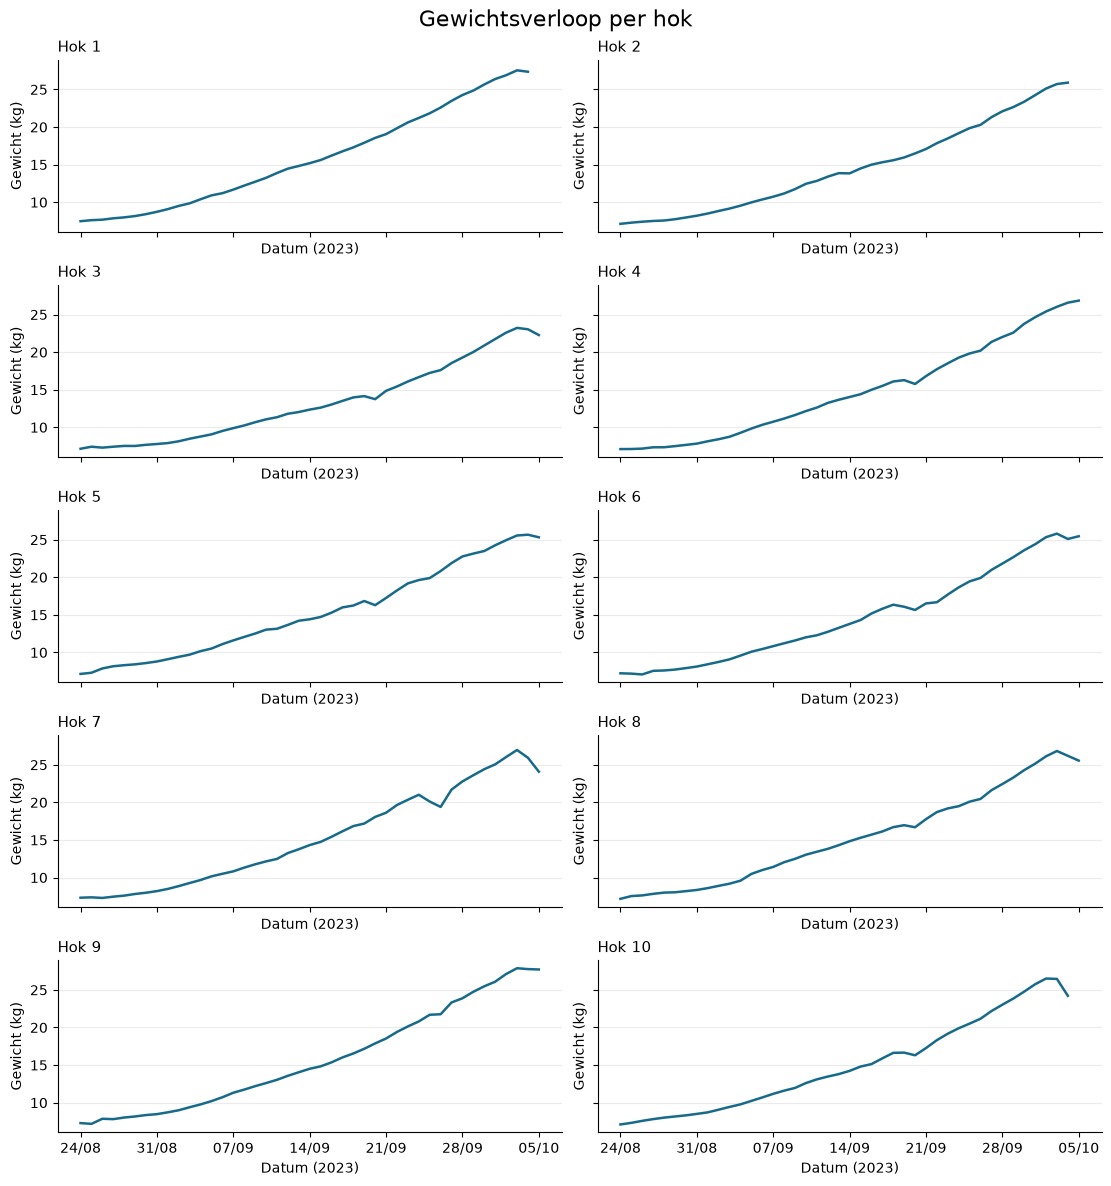

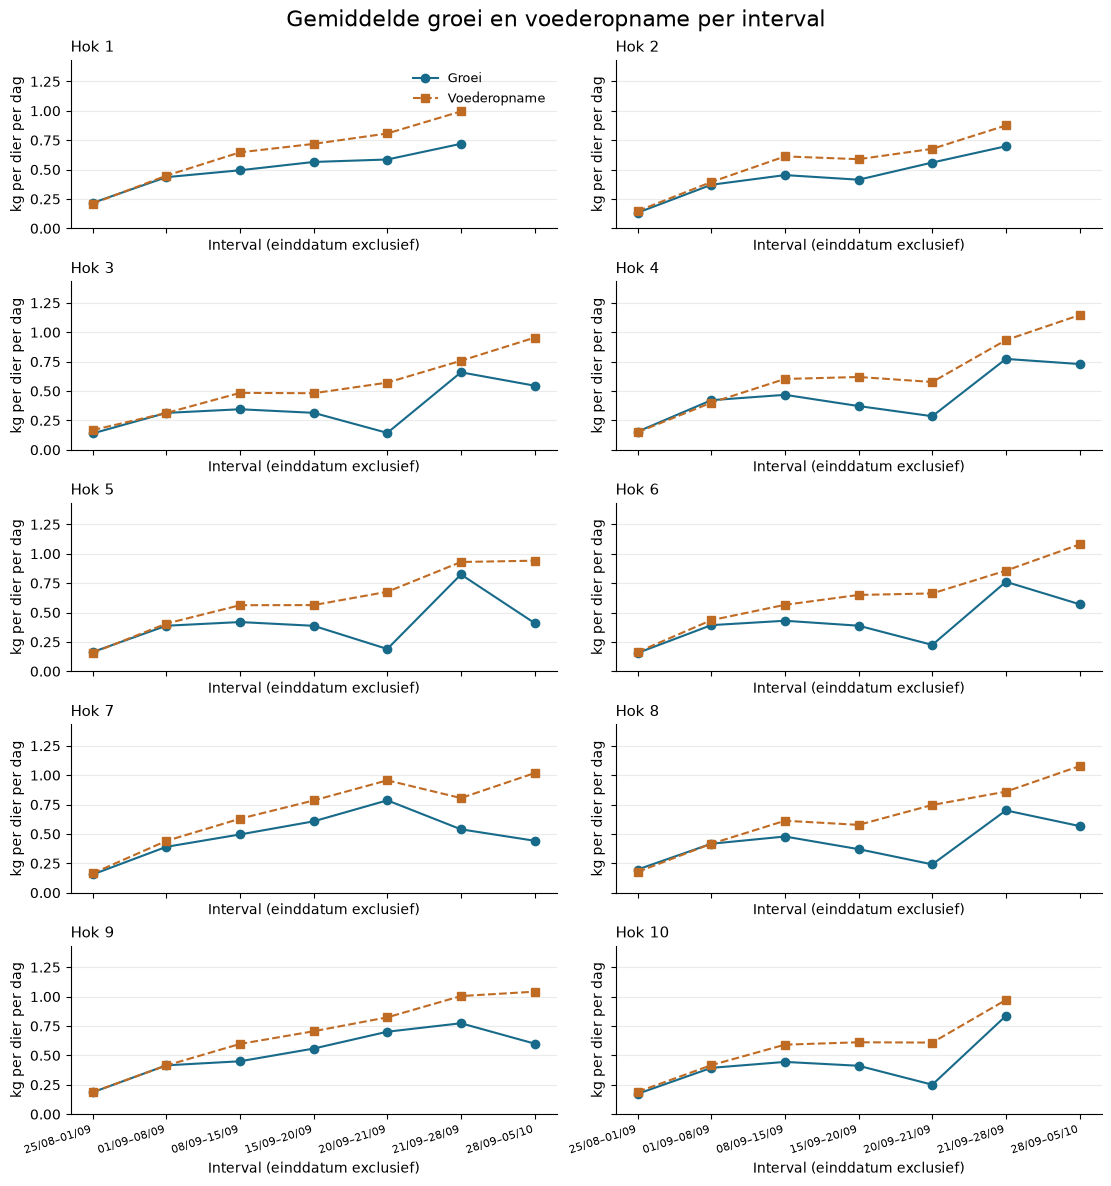

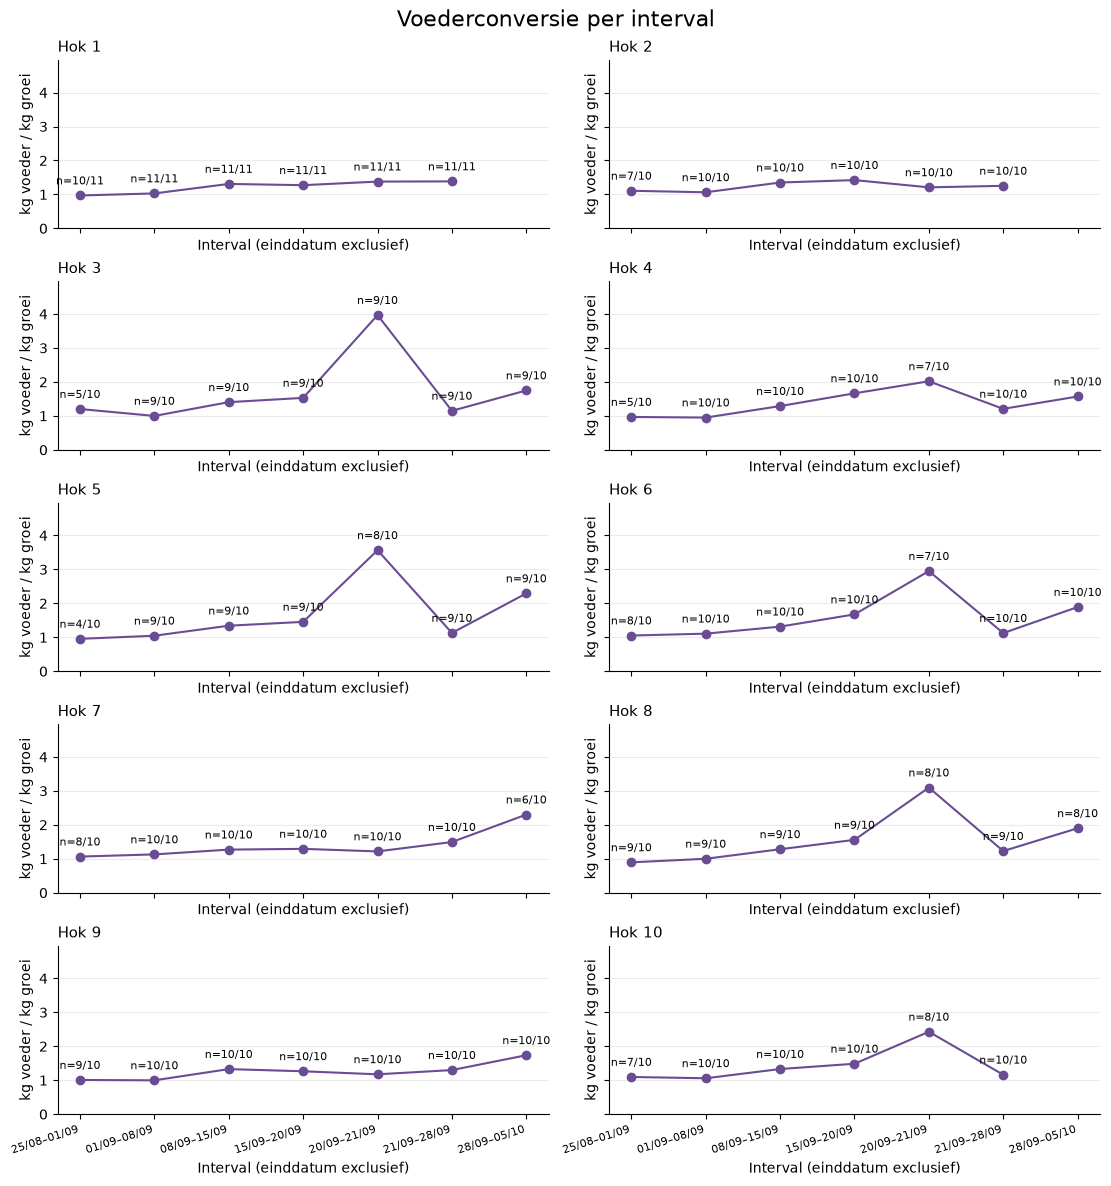

In [5]:
figuren = {
    "08_gewichtsverloop.png": gewichtsfiguur(resultaat["dag"]),
    "08_groei_en_voederopname.png": intervalfiguur(resultaat["hokintervallen"], kilogram=True),
    "08_voederconversie.png": intervalfiguur(resultaat["hokintervallen"], "conversie"),
}
for naam, fig in figuren.items():
    fig.savefig(inlever / naam, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Doe-opdracht.** Kies twee hokken waarvan je de ontwikkeling wilt vergelijken. Stel hieronder de twee hoknummers en een periode in: `basis`, `aanvulling` of `geheel`. Bekijk hun dekking, groei, voederopname en conversie samen. Vergelijk minstens één hok dat je in 07 al onderzocht.

</div>

In [6]:
# Kies twee verschillende hoknummers als tekst, bijvoorbeeld ["1", "9"].
# Kies daarna een van de drie perioden.
# mijn_hokken = ...
# mijn_periode = ...

In [7]:
mijn_hokken = ["4", "9"]
mijn_periode = "aanvulling"

In [8]:
assert len(set(mijn_hokken)) == 2 and set(mijn_hokken) <= set(perioden.hok)
assert mijn_periode in {"basis", "aanvulling", "geheel"}
eigen_selectie = perioden[perioden.hok.isin(mijn_hokken) & perioden.periode.eq(mijn_periode)]
display(eigen_selectie[kolommen].round(3))
for r in eigen_selectie.itertuples():
    print(f"Hok {r.hok}: {r.groei_g_dier_dag:.1f} g groei/dier/dag, "
          f"{r.voeder_g_dier_dag:.1f} g voeder/dier/dag, conversie {r.voederconversie:.3f}, "
          f"{r.dieren_bruikbaar}/{r.dieren_populatie} dieren.")

,hok,periode,dagen,dieren_bruikbaar,dieren_populatie,groei_g_dier_dag,voeder_g_dier_dag,voederconversie
14,4,aanvulling,14,10,10,751.580,1039.764,1.383
19,9,aanvulling,14,10,10,686.832,1023.514,1.490


Hok 4: 751.6 g groei/dier/dag, 1039.8 g voeder/dier/dag, conversie 1.383, 10/10 dieren.
Hok 9: 686.8 g groei/dier/dag, 1023.5 g voeder/dier/dag, conversie 1.490, 10/10 dieren.


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 4.** Welk verschil tussen de twee gekozen hokken vind je relevant voor de bedrijfsvoering?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 4):**

*Voeg hier je antwoord in. Tip: Noem concrete waarden uit de tabel, de periode, dekking en een mogelijke andere verklaring.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 4**

Van 21 september tot 5 oktober groeit hok 4 0.752 kg per dier per dag, bij 1.040 kg voeder en een conversie van 1.383. Voor hok 9 zijn de waarden 0.687, 1.024 en 1.490. Er zijn respectievelijk 10 en 10 bruikbare dieren. Hok 4 combineert in deze periode meer groei met een lagere conversie. Gezondheid, uitgangsgewicht en dekking kunnen eveneens verschillen. Dit bewijst geen behandelingstoewijzing.

</div>

<div style="background-color:#e3f2fd;color:#0d47a1;border-left:5px solid #1976d2;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Facultatieve verkenning</strong><br>Maak dezelfde vergelijking met alleen dieren die in zowel de basisperiode als de aanvulling bruikbaar zijn. Zo onderzoek je of een andere samenstelling van de groep een deel van het verschil verklaart. De hoofdresultaten blijven behouden.</div>

In [9]:
# Facultatief: gebruik resultaat["dierperioden"].
# Zoek de dier_id's met bruikbaar == True in zowel basis als aanvulling.
# Selecteer die dieren en gebruik vat_hokken_samen per periode.
# Vergelijk vooral dieren_bruikbaar en voederconversie met de hoofdroute.

In [10]:
d = resultaat["dierperioden"]
sets = [set(d.loc[d.periode.eq(p) & d.bruikbaar, "dier_id"]) for p in ("basis", "aanvulling")]
zelfde_dieren = sets[0] & sets[1]
vaste_groep = pd.concat([
    vat_hokken_samen(g[g.dier_id.isin(zelfde_dieren)]).assign(periode=p)
    for p, g in d[d.periode.isin(["basis", "aanvulling"])].groupby("periode")
], ignore_index=True)
display(vaste_groep[kolommen].round(3))

,hok,periode,dagen,dieren_bruikbaar,dieren_populatie,groei_g_dier_dag,voeder_g_dier_dag,voederconversie
0,3,aanvulling,14,5,5,591.528,872.214,1.475
1,4,aanvulling,14,5,5,745.039,1034.600,1.389
2,5,aanvulling,14,4,4,688.438,1020.339,1.482
3,6,aanvulling,14,8,8,657.104,973.464,1.481
4,7,aanvulling,14,4,4,469.436,840.750,1.791
5,8,aanvulling,14,8,8,637.493,970.527,1.522
6,9,aanvulling,14,9,9,673.589,1005.381,1.493
7,3,basis,26,5,5,279.482,363.908,1.302
8,4,basis,26,5,5,346.426,422.546,1.220
9,5,basis,26,4,4,377.428,440.000,1.166


## 8. Van hokpatronen naar een voederkeuze

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Je hebt nu de metingen van twee afzonderlijke systemen gecombineerd. Daarmee kun je een bedrijfsbeslissing onderbouwen die met alleen voederopname of alleen gewicht moeilijker te beoordelen is. De beschikbare strategieën verschillen in het eiwitgehalte van het eerste voeder en in het schakelmoment naar een gemeenschappelijk vervolgvoeder.

</div>

| Keuze | Eerste voeder (g ruw eiwit/kg) | Overgang naar vervolgvoeder | Vervolgvoeder (g/kg) |
|---|---:|---|---:|
| HRE10 | 188 | Na 10 dagen | 179 |
| HRE18 | 188 | Na 18 dagen | 179 |
| LRE10 | 162 | Na 10 dagen | 179 |
| LRE18 | 162 | Na 18 dagen | 179 |

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Een groeiverschil kan aanleiding geven tot een hypothese over de toegepaste strategie. Het onthult het eiwitgehalte niet rechtstreeks. De eerste intervallen zijn het meest relevant voor een mogelijk schakelmoment. In de latere periode krijgen de groepen het gemeenschappelijke vervolgvoeder. Achterblijvende groei kan dan bijvoorbeeld worden ingehaald, maar een inhaalpatroon bewijst de oorzaak niet.

**Doe-opdracht.** Vul voor ieder hok een vermoedelijke strategie in. Kies ook bij twijfel de best passende strategie. Vermeld alternatieven en onzekerheid in je argument. Er zijn drie HRE18-hokken, drie LRE18-hokken, twee HRE10-hokken en twee LRE10-hokken. Controleer of je toewijzing deze aantallen respecteert. Noteer per hok een concreet patroon en geef je zekerheid aan als `laag`, `matig` of `hoog`. Een toetsbare hypothese is nuttiger dan een stellige toewijzing zonder bewijs. Gebruik de meetgrafieken, geen behandelingssleutel.

Kies vervolgens één van de vier strategieën voor toekomstig gebruik op het bedrijf. Maak duidelijk of je een definitieve bedrijfskeuze of een beperkte proef invoert. Benoem wat je op basis van de cijfers verwacht, welke onzekerheid blijft bestaan en welke aanvullende informatie je eerst zou controleren. Gezondheid, uitval, voederprijzen en karkas- of afleverdoelen zijn niet volledig uit deze twee gegevensstromen af te leiden.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**De voerwissels als periodegrenzen.** HRE betekent hoog ruw eiwit en LRE laag ruw eiwit. De getallen 10 en 18 geven het aantal dagen tot de overgang aan. We nemen 24 augustus 2023 om 00:00 als dag 0. Dag 10 valt dan op 3 september en dag 18 op 11 september. Dit zijn analysegrenzen, geen uit de metingen bewezen exacte wisseluren.

Tussen dag 10 en 18 krijgen de vroeg geschakelde groepen al het gemeenschappelijke voeder. De laat schakelende groepen krijgen nog hun oorspronkelijke voeder. Daarom is deze periode geschikt om een mogelijk verschil tussen HRE18 en LRE18 te onderzoeken. We gebruiken dezelfde gewichtsinterpolatie en selectie als in 07. Dag 0 is onvolledig en wordt weggelaten. De laatste grens ligt op dag 27, binnen de oorspronkelijke gegevensperiode.

**Stap 1.** Vergelijk dag 1–10, dag 10–18 en dag 18–27. Controleer telkens groei, opname, conversie en het aantal bruikbare dieren. Groei en opname worden hieronder in kg per dier per dag getoond. Conversie blijft kg voeder per kg groei.

</div>

C:\Users\jerdgroo\AppData\Local\Temp\ipykernel_89632\3435664647.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(fasen[fasekolommen].round(3))


,hok,interval,vanaf,tot,dieren_bruikbaar,dieren_populatie,groei_kg_dier_dag,voeder_kg_dier_dag,voederconversie
0,1,1,2023-08-25,2023-09-03,10,11,0.256,0.242,0.945
1,1,2,2023-09-03,2023-09-11,11,11,0.484,0.532,1.100
2,1,3,2023-09-11,2023-09-20,11,11,0.519,0.701,1.351
3,10,1,2023-08-25,2023-09-03,7,10,0.204,0.214,1.049
4,10,2,2023-09-03,2023-09-11,10,10,0.451,0.504,1.119
5,10,3,2023-09-11,2023-09-20,10,10,0.412,0.609,1.477
6,2,1,2023-08-25,2023-09-03,7,10,0.173,0.182,1.051
7,2,2,2023-09-03,2023-09-11,10,10,0.456,0.493,1.079
8,2,3,2023-09-11,2023-09-20,10,10,0.393,0.604,1.537
9,3,1,2023-08-25,2023-09-03,5,10,0.156,0.176,1.128


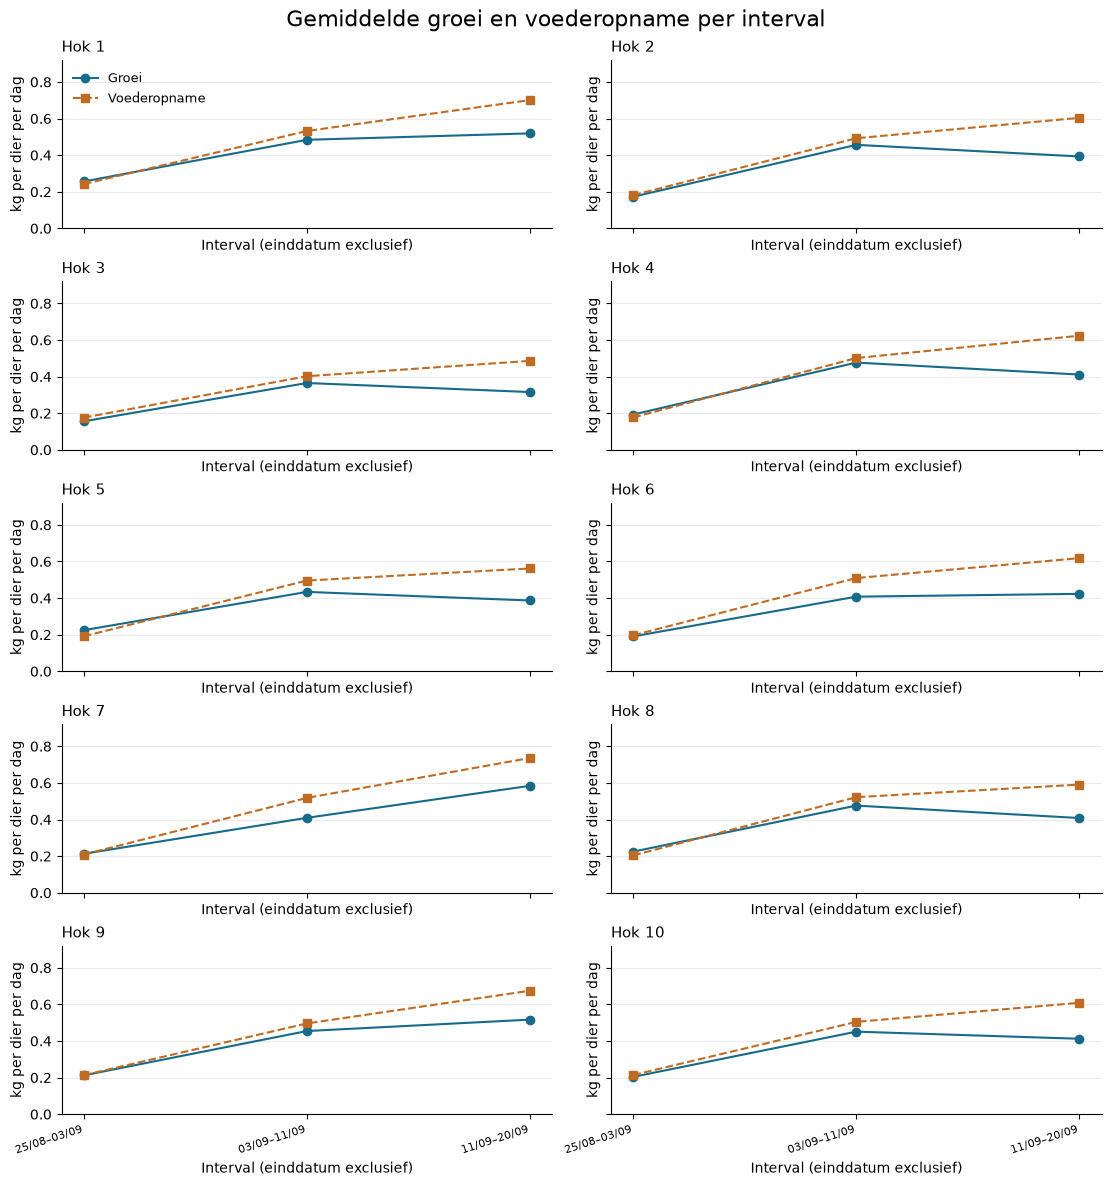

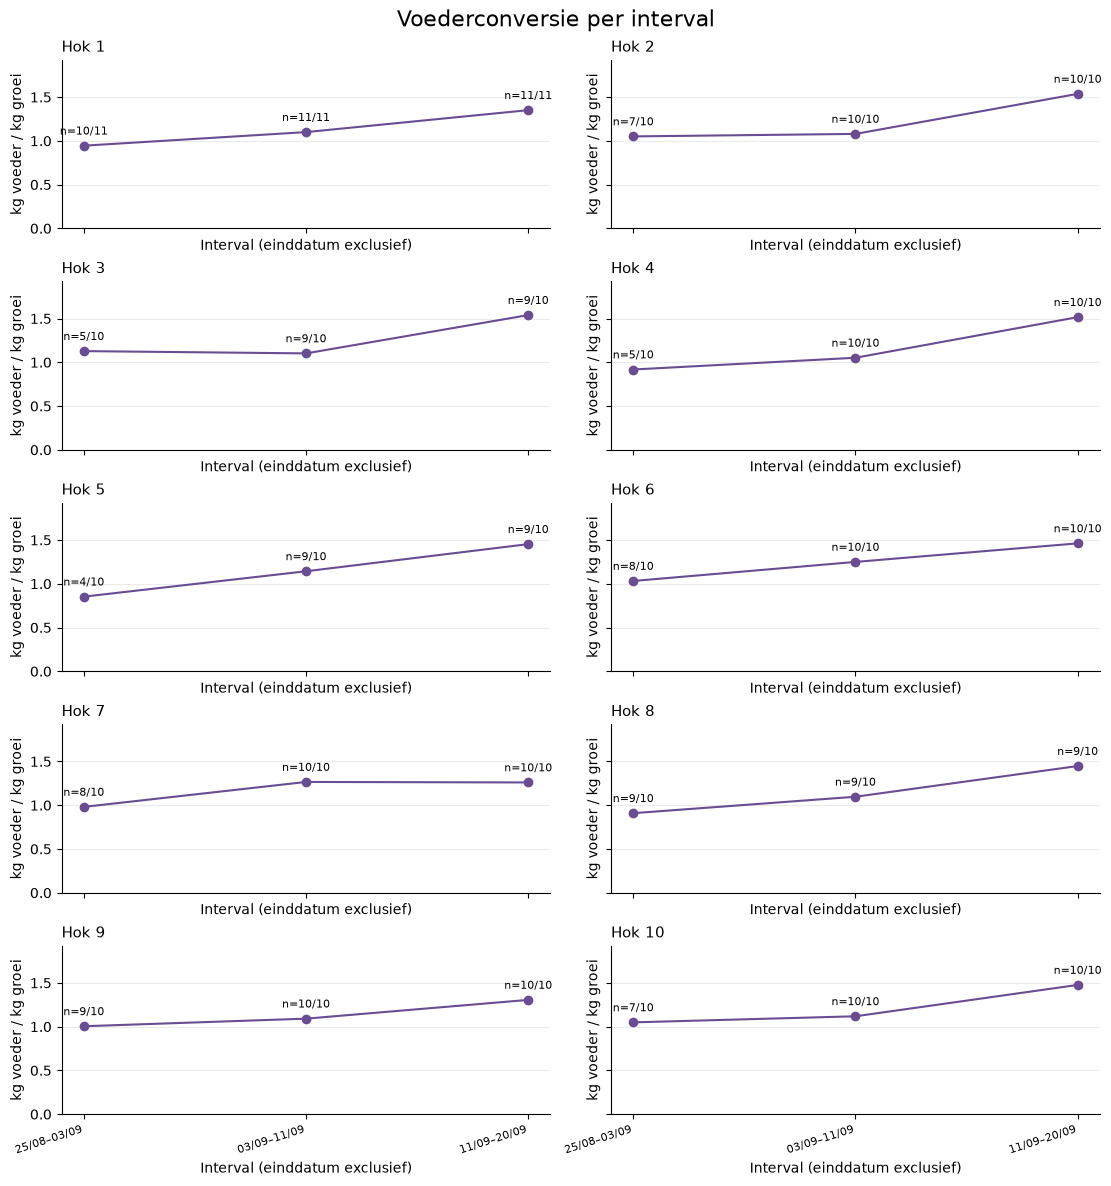

C:\Users\jerdgroo\AppData\Local\Temp\ipykernel_89632\3435664647.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(rangorde[fasekolommen].round(3))


,hok,interval,vanaf,tot,dieren_bruikbaar,dieren_populatie,groei_kg_dier_dag,voeder_kg_dier_dag,voederconversie
1,1,2,2023-09-03,2023-09-11,11,11,0.484,0.532,1.100
13,4,2,2023-09-03,2023-09-11,10,10,0.477,0.501,1.052
25,8,2,2023-09-03,2023-09-11,9,10,0.476,0.522,1.097
7,2,2,2023-09-03,2023-09-11,10,10,0.456,0.493,1.079
28,9,2,2023-09-03,2023-09-11,10,10,0.454,0.496,1.091
4,10,2,2023-09-03,2023-09-11,10,10,0.451,0.504,1.119
16,5,2,2023-09-03,2023-09-11,9,10,0.434,0.496,1.143
22,7,2,2023-09-03,2023-09-11,10,10,0.409,0.518,1.266
19,6,2,2023-09-03,2023-09-11,10,10,0.408,0.509,1.250
10,3,2,2023-09-03,2023-09-11,9,10,0.365,0.402,1.102


In [11]:
from analyse_07 import selecteer, daggewichten, bereken_intervallen
gewichten_fase, voer_fase, populatie_fase, _, _ = selecteer(data)
dag_fase = daggewichten(gewichten_fase)
proefstart = pd.Timestamp("2023-08-24")
grenzen = [proefstart + pd.Timedelta(days=d) for d in (1, 10, 18, 27)]
fase_dieren = bereken_intervallen(dag_fase, voer_fase, populatie_fase, grenzen)
fasen = vat_hokken_samen(fase_dieren)
fasen["groei_kg_dier_dag"] = fasen.groei_g_dier_dag / 1000
fasen["voeder_kg_dier_dag"] = fasen.voeder_g_dier_dag / 1000
fasekolommen = ["hok", "interval", "vanaf", "tot", "dieren_bruikbaar", "dieren_populatie",
                "groei_kg_dier_dag", "voeder_kg_dier_dag", "voederconversie"]
display(fasen[fasekolommen].round(3))
for soort in ("groei_voeder", "conversie"):
    fig = intervalfiguur(fasen, soort, kilogram=True)
    fig.savefig(inlever / ("08_voederfasen_" + soort + ".png"), dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)
rangorde = fasen[fasen.interval.eq(2)].sort_values("groei_kg_dier_dag", ascending=False)
display(rangorde[fasekolommen].round(3))

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Stap 2.** Gebruik de rangorde van de groei tussen dag 10 en 18 als eerste hypothese: drie snelgroeiende hokken als kandidaat HRE18 en drie traaggroeiende als kandidaat LRE18. Controleer vervolgens of hun opname en conversie die interpretatie ondersteunen. Een lage groei samen met een lage opname is een andere situatie dan een lage groei bij een hoge opname. Rangschikken is hier een verkenning, geen algemene methode om een voederrecept te herkennen.

**Stap 3.** Vergelijk voor de vier resterende hokken de periode vóór dag 10. Een lagere conversie kan een aanwijzing voor een betere benutting zijn, maar legt het eiwitgehalte niet vast. Formuleer voor twee hokken HRE10 en voor twee LRE10 als beste hypothese. Bekijk ook de veranderingen na dag 18. Een verandering is niet automatisch een voedereffect: leeftijd, gezondheid, beginmassa en de selectie van dieren spelen mee. De vergelijkingen gebruiken niet noodzakelijk dezelfde dieren in elke fase. Raadpleeg `fase_dieren` om de samenstelling te controleren.

**Eigen onderzoek.** Kies één twijfelgeval en leg uit welke andere toewijzing ook verdedigbaar is. Je kunt bijvoorbeeld kortere perioden rond dag 10 of 18 vergelijken, of dezelfde dieren in alle perioden behouden. Bewaar de hoofdresultaten. Een korter venster geeft meer tijdsdetail, maar is gevoeliger voor meetvariatie. Blijf geen vensters aanpassen totdat een gewenste uitkomst verschijnt.

</div>

In [12]:
hypothesen = pd.DataFrame({
    "hok": hokvolgorde(perioden.hok),
    "strategie": "",
    "zekerheid": "laag",
    "argument": "",
})
display(hypothesen)
# Vul argumenten en strategieën in met bijvoorbeeld:
# hypothesen.loc[hypothesen.hok == "1", "argument"] = "Mijn waarneming ..."
# Kies één strategie en formuleer je onderbouwing.
# gekozen_strategie = ...
# bedrijfsadvies = ...

,hok,strategie,zekerheid,argument
0,1,,laag,
1,2,,laag,
2,3,,laag,
3,4,,laag,
4,5,,laag,
5,6,,laag,
6,7,,laag,
7,8,,laag,
8,9,,laag,
9,10,,laag,


In [13]:
# Een reproduceerbare voorbeeldhypothese, zonder behandelingssleutel.
assert len(rangorde) == 10 and rangorde.groei_kg_dier_dag.notna().all()
kandidaten_hoog = set(rangorde.head(3).hok)
kandidaten_laag = set(rangorde.tail(3).hok)
overige = set(rangorde.hok) - kandidaten_hoog - kandidaten_laag
vroeg = fasen[fasen.interval.eq(1) & fasen.hok.isin(overige)].sort_values("voederconversie")
assert vroeg.voederconversie.notna().all()
kandidaten_vroeg_hoog = set(vroeg.head(2).hok)
for i, h in enumerate(hypothesen.hok):
    r = rangorde[rangorde.hok.eq(h)].iloc[0]
    strategie = ("HRE18" if h in kandidaten_hoog else "LRE18" if h in kandidaten_laag
                 else "HRE10" if h in kandidaten_vroeg_hoog else "LRE10")
    hypothesen.loc[i, "strategie"] = strategie
    hypothesen.loc[i, "zekerheid"] = "matig" if h not in overige else "laag"
    argument = (f"Dag 10–18: groei {r.groei_kg_dier_dag:.3f} kg/dier/dag, "
                f"opname {r.voeder_kg_dier_dag:.3f} kg/dier/dag, conversie {r.voederconversie:.3f}, "
                f"{r.dieren_bruikbaar}/{r.dieren_populatie} dieren. ")
    if h in overige:
        v = vroeg[vroeg.hok.eq(h)].iloc[0]
        argument += (f"Voorlopige verdeling van de vier resterende hokken op conversie vóór dag 10: "
                     f"{v.voederconversie:.3f} bij {v.dieren_bruikbaar}/{v.dieren_populatie} dieren. "
                     "Verwisseling tussen HRE10 en LRE10 blijft aannemelijk.")
    else:
        argument += ("Toewijzing op de groeirangorde in de fase vóór de late wissel. "
                     "Opname en conversie ondersteunen niet elk hok even sterk. "
                     "Verschillen in gezondheid of uitgangsgewicht blijven alternatieve verklaringen.")
    hypothesen.loc[i, "argument"] = argument
gekozen_strategie = "HRE18"
keuze = rangorde[rangorde.hok.isin(kandidaten_hoog)]
bedrijfsadvies = (
    "Ik kies HRE18 voor de volgende ronde, met groei als eerste bedrijfsdoel. "
    f"De kandidaat-hokken groeien tussen dag 10 en 18 gemiddeld {keuze.groei_kg_dier_dag.mean():.3f} kg per dier per dag, "
    f"bij {keuze.voeder_kg_dier_dag.mean():.3f} kg voeder per dier per dag. "
    f"Hun afzonderlijke conversies liggen tussen {keuze.voederconversie.min():.3f} en {keuze.voederconversie.max():.3f}. "
    "Ik weeg groei, opname en conversie samen en controleer ook het herstel na de wissel en de aanvullende periode. "
    "De labels zijn hypotheses, geen bewezen behandelingseffect. Verschillen in dekking en gezondheid kunnen meespelen. "
    "Voor aankoop vergelijk ik werkelijke voederprijzen, gezondheid en uitval en de waarde van eerder afleveren. "
    "Een economisch optimale strategie is met alleen deze gegevens niet vast te stellen."
)

display(hypothesen)
print(bedrijfsadvies)

,hok,strategie,zekerheid,argument
0,1,HRE18,matig,"Dag 10–18: groei 0.484 kg/dier/dag, opname 0.5..."
1,2,LRE10,laag,"Dag 10–18: groei 0.456 kg/dier/dag, opname 0.4..."
2,3,LRE18,matig,"Dag 10–18: groei 0.365 kg/dier/dag, opname 0.4..."
3,4,HRE18,matig,"Dag 10–18: groei 0.477 kg/dier/dag, opname 0.5..."
4,5,HRE10,laag,"Dag 10–18: groei 0.434 kg/dier/dag, opname 0.4..."
5,6,LRE18,matig,"Dag 10–18: groei 0.408 kg/dier/dag, opname 0.5..."
6,7,LRE18,matig,"Dag 10–18: groei 0.409 kg/dier/dag, opname 0.5..."
7,8,HRE18,matig,"Dag 10–18: groei 0.476 kg/dier/dag, opname 0.5..."
8,9,HRE10,laag,"Dag 10–18: groei 0.454 kg/dier/dag, opname 0.4..."
9,10,LRE10,laag,"Dag 10–18: groei 0.451 kg/dier/dag, opname 0.5..."


Ik kies HRE18 voor de volgende ronde, met groei als eerste bedrijfsdoel. De kandidaat-hokken groeien tussen dag 10 en 18 gemiddeld 0.479 kg per dier per dag, bij 0.519 kg voeder per dier per dag. Hun afzonderlijke conversies liggen tussen 1.052 en 1.100. Ik weeg groei, opname en conversie samen en controleer ook het herstel na de wissel en de aanvullende periode. De labels zijn hypotheses, geen bewezen behandelingseffect. Verschillen in dekking en gezondheid kunnen meespelen. Voor aankoop vergelijk ik werkelijke voederprijzen, gezondheid en uitval en de waarde van eerder afleveren. Een economisch optimale strategie is met alleen deze gegevens niet vast te stellen.


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Facultatieve verdieping: lysine.** De instructiepresentatie geeft op slide 29 een voorbeeld om lysinebehoefte voor onderhoud en groei te vergelijken met de opname. Je kunt daarmee onderzoeken of een beperkte groei bij het aminozuuraanbod past. Dit is geen verplicht onderdeel. Licht bij zo'n uitbreiding je aannames, eenheden en onzekerheid over de voederstrategie toe. Bereken geen schijnbaar exacte benutting wanneer de voersamenstelling nog een hypothese is.

</div>

<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Interpretatie</strong><br>Een volledige toewijzing blijft een hypothese. Geef voor ieder hok je beste keuze, maar verberg twijfel niet. Een correcte groepsgrootte bewijst niet dat de individuele hokken correct zijn ingedeeld. Zonder bekende behandelingstoewijzing en aanvullende bedrijfsgegevens is de meest winstgevende strategie niet vast te stellen.</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 5.** Wat heeft de integratie van beide systemen aan je beslissing toegevoegd, en welke vraag blijft onbeantwoord?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 5):**

*Voeg hier je antwoord in. Tip: Verbind een berekende verhouding met een concreet ontbrekend gegeven.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 5**

Alleen de weeggegevens tonen groei. Alleen de voedergegevens tonen opname. Door beide voor dezelfde dieren en dezelfde periode te koppelen kan ik voederconversie beoordelen en een vervolgproef opvolgen. Ik kan met deze bestanden nog niet vaststellen welke strategie het meest winstgevend is, omdat de werkelijke kosten en de zekere koppeling tussen hok en behandeling ontbreken.

</div>

## 9. Resultaten automatisch bewaren en inleveren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 08)

De afsluitcel bewaart je berekeningen, hokhypothesen, advies en technische controles. Zij maakt ook een consistente SQLite-snapshot van de analysedatabase met de back-upfunctie. Het bestand wordt gecomprimeerd als `08_analysedatabase.db.gz`, zodat het samen met de andere resultaten kan worden ingeleverd. De beginsituatie uit 07 blijft behouden.

Het automatische controlebestand legt vast welke gegevens zijn verwerkt en welke berekeningen zijn uitgevoerd. Het beoordeelt niet zelfstandig of jouw biologische interpretatie juist is. De ingevulde antwoorden en het advies blijven daarom onderdeel van de beoordeling.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Wat lever je in?** Bewaar de grafieken voor alle tien hokken van groei en voederopname in kg per dier per dag, en conversie in kg voeder per kg groei. De afsluitcel schrijft `hok_voederstrategie.csv` met precies twee kolommen: hoknummer en voederstrategie. De argumenten en onzekerheid blijven apart in `hokhypothesen.csv`. `bedrijfsadvies.txt` bevat je gekozen strategie en onderbouwing voor dit bedrijf. Samen met je uitgevoerde notebook en automatische controles vormen deze bestanden de inlevering. Er is geen afzonderlijk technisch verslag nodig.

</div>

In [14]:
toegelaten = {"HRE10", "HRE18", "LRE10", "LRE18"}
assert gekozen_strategie in toegelaten and len(bedrijfsadvies.strip()) >= 80
assert set(hypothesen.hok) == set(perioden.hok) and not hypothesen.hok.duplicated().any()
assert hypothesen.strategie.isin(toegelaten).all()
assert hypothesen.zekerheid.isin({"laag", "matig", "hoog"}).all()
assert hypothesen.argument.str.len().ge(30).all(), "Geef voor ieder hok een inhoudelijk argument."
assert hypothesen.strategie.value_counts().to_dict() == {"HRE18": 3, "LRE18": 3, "HRE10": 2, "LRE10": 2}
uitvoermap = inlever / "resultaten_08"
uitvoermap.mkdir(exist_ok=True)
for naam in ("hokintervallen", "dierintervallen", "hokperioden", "dierperioden", "audit"):
    resultaat[naam].to_csv(uitvoermap / (naam + ".csv"), index=False, float_format="%.12g", lineterminator="\n")
hypothesen.to_csv(uitvoermap / "hokhypothesen.csv", index=False, lineterminator="\n")
hypothesen[["hok", "strategie"]].rename(columns={"hok": "hoknummer", "strategie": "voederstrategie"}).to_csv(uitvoermap / "hok_voederstrategie.csv", index=False)
fasen[fasekolommen].to_csv(uitvoermap / "voederfasen.csv", index=False)
(uitvoermap / "bedrijfsadvies.txt").write_text(gekozen_strategie + "\n\n" + bedrijfsadvies + "\n", encoding="utf-8")
snapshotinfo = snapshot(analysepad, inlever / "08_analysedatabase.db.gz")
assert snapshotinfo["bytes"] < 95_000_000, "Snapshot te groot voor gewone Git-opslag. Vraag hulp."
lees_basis(inlever / "beginsituatie_07")
verslag = {
    "deelnemerscode": deelnemer, "branch": branch, "rol": rol,
    "gecontroleerd_op_utc": datetime.now(timezone.utc).isoformat(),
    "bronnen": eindmanifest, "excel_import": importcontrole, "excel_herhaling": herhaalimport,
    "mqtt_bevestigd": gepubliceerd, "server_gelijk_aan_bronnen": servermeta["bronnen"] == verwacht,
    "api_import": api_import, "api_herhaling": api_herhaling,
    "basis_ongewijzigd": True, "methode": basisinfo["methode"],
    "bruikbare_dieren_per_interval": resultaat["dierintervallen"].groupby("interval").bruikbaar.sum().astype(int).to_dict(),
    "gekozen_hokken": mijn_hokken, "gekozen_periode": mijn_periode,
    "gekozen_strategie": gekozen_strategie, "bedrijfsadvies": bedrijfsadvies,
    "snapshot": snapshotinfo,
    "resultaatbestanden": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(uitvoermap.iterdir()) if p.is_file()},
}
(inlever / "08_eindcontrole.json").write_text(json.dumps(verslag, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Bewaard: tabellen, drie figuren, hokhypothesen, advies, databasesnapshot en 08_eindcontrole.json.")
print("Snapshot:", round(snapshotinfo["bytes"] / 1_000_000, 1), "MB")

Bewaard: tabellen, drie figuren, hokhypothesen, advies, databasesnapshot en 08_eindcontrole.json.
Snapshot: 52.1 MB


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Source Control)

**Stap 1.** Kies **File → Save All**. Controleer of je antwoorden, eigen keuze, tabel met hokhypothesen en bedrijfsadvies zijn ingevuld. Bekijk of alle tien hokken voorkomen in de grafieken van groei/voederopname en voederconversie.

**Stap 2.** Open **Source Control**. Neem je ingevulde notebook en de nieuwe bestanden in `gegevens/inlevering/` op in de commit. Behoud ook `beginsituatie_07/`. Werkbestanden en wachtwoorden horen niet bij de inlevering. Gebruik bijvoorbeeld de committekst `Notebook 08: aanvulling en voederadvies`.

**Stap 3.** Kies **Commit** en daarna **Push** of **Sync Changes**. Open je eigen branch op GitHub en controleer of de nieuwe commit en bestanden aanwezig zijn. Alleen opslaan in Codespaces is niet voldoende.

**Stap 4.** Meld dat je de reeks hebt afgerond. Bewaar de snapshot en resultaten voordat de oefenservers worden verwijderd. De docent stemt het moment van verwijdering af. Deze notebook verwijdert geen server.

</div>

<div style="background-color:#fff8e1;color:#6d4c00;border-left:5px solid #f9a825;padding:14px;margin:12px 0;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Stop je Codespace</strong><br>Stop de Codespace na het bewaren en pushen via GitHub → Codespaces → de drie puntjes → Stop codespace. Een draaiende Codespace verbruikt beschikbare uren. Een DigitalOcean-Droplet stopt niet vanzelf na een maand. Ook een uitgeschakelde maar niet verwijderde Droplet kan kosten blijven veroorzaken. Stem de definitieve verwijdering af met de docent.</div>

## Problemen oplossen

| Melding of waarneming | Wat controleer je? |
|---|---|
| Excel-bestand gewijzigd | Download de vrijgegeven repositoryversie opnieuw. Sla lange identificaties niet als getallen op. |
| Bestaande meting verschilt | Behoud je werkbestand en back-up. Vraag hulp voordat je gegevens vervangt. |
| Serverinhoud verschilt | Zijn beide ontvangers actief en beide publicaties klaar? Gebruik de actuele partnercontrole. Herpubliceer na herstel. |
| API niet bereikbaar of HTTP 401 | Controleer diensten, certificaat en `API-Droplet wachtwoord` volgens 06. |
| Beginsituatie verschilt | Overschrijf 07 niet. Controleer of bronrecords of rekenregels gewijzigd zijn. |
| Een conversie ontbreekt | Bekijk `dierintervallen` en de kolom `reden`. Ontbrekende dekking is geen nulopname. |
| Geen duidelijke behandelingsgroepen | Beschrijf de onderzochte patronen en onzekerheid. De grafieken garanderen geen unieke toewijzing. |